# BI overview: traffic, ATFM delay and disruption at 12 German airports

Descriptive analysis of `data/processed/airport_day.csv` (one row per airport-day, 2014 to 2025). Network KPIs are ratios of sums (for example total delay / total arrivals), not averages of daily ratios, so large airports are weighted by their traffic. A day is disrupted when at least 2% of arrivals had more than 15 minutes of ATFM delay, and severely disrupted from 10%.

Weather comparisons only use days that have a reading for the weather variable involved. Traffic pressure compares each day with the airport's median arrivals in the same year, so the COVID drop in 2020 and 2021 does not dominate the traffic groups.


In [1]:
# ============================================================
# 0. IMPORT LIBRARIES
# ============================================================
# pandas for the airport-day table, numpy for bin edges, matplotlib for the charts.

import pandas as pd

import numpy as np

import matplotlib.pyplot as plt
# ============================================================
# 1. LOAD THE DATASET
# ============================================================
# One row per airport-day (12 airports, 2014-2025). low_memory=False makes pandas
# read the whole file before guessing column types, which avoids mixed-type warnings.

df = pd.read_csv("../data/processed/airport_day.csv", low_memory=False)

# Convert date from text to datetime format
df["date"] = pd.to_datetime(df["date"])

# Display the first five observations
print(df.head())

  airport_icao       date         airport_name  dwd_station  arrivals  \
0         EDDC 2014-01-01              Dresden         1048      15.0   
1         EDDF 2014-01-01            Frankfurt         1420     362.0   
2         EDDG 2014-01-01  Muenster-Osnabrueck         1766       3.0   
3         EDDH 2014-01-01              Hamburg         1975     103.0   
4         EDDK 2014-01-01         Cologne-Bonn         2667      70.0   

   atfm_delay_min  arrivals_atfm_delayed  arrivals_atfm_delayed_15  \
0             0.0                    0.0                       0.0   
1             0.0                    0.0                       0.0   
2             0.0                    0.0                       0.0   
3             0.0                    0.0                       0.0   
4             0.0                    0.0                       0.0   

  atfm_version  delay_accident_min  ...  arrivals_lag7  \
0           v1                 0.0  ...            NaN   
1           v1          

In [2]:
# ============================================================
# 2. DATASET OVERVIEW
# ============================================================
# Basic checks before any KPI: size, period covered, which airports are included,
# and the type and non-null count of every column.

print("Dataset shape:")
print(df.shape)

print("\nDate range:")
print(df["date"].min(), "to", df["date"].max())

print("\nNumber of airports:")
print(df["airport_icao"].nunique())

print("\nAirports:")
print(sorted(df["airport_name"].unique()))

print("\nColumn information:")
df.info()

Dataset shape:
(52596, 79)

Date range:
2014-01-01 00:00:00 to 2025-12-31 00:00:00

Number of airports:
12

Airports:
['Bremen', 'Cologne-Bonn', 'Dresden', 'Duesseldorf', 'Frankfurt', 'Hamburg', 'Hannover', 'Leipzig-Halle', 'Muenster-Osnabrueck', 'Munich', 'Nuremberg', 'Stuttgart']

Column information:
<class 'pandas.DataFrame'>
RangeIndex: 52596 entries, 0 to 52595
Data columns (total 79 columns):
 #   Column                              Non-Null Count  Dtype         
---  ------                              --------------  -----         
 0   airport_icao                        52596 non-null  str           
 1   date                                52596 non-null  datetime64[us]
 2   airport_name                        52596 non-null  str           
 3   dwd_station                         52596 non-null  int64         
 4   arrivals                            52558 non-null  float64       
 5   atfm_delay_min                      52558 non-null  float64       
 6   arrivals_atfm_del

In [3]:
# ============================================================
# 3. OVERALL KPI SUMMARY
# ============================================================
# Headline KPIs for all 12 airports together. Intensity is a ratio of sums
# (total delay / total arrivals), so busy days and airports keep their real weight.

total_airport_days = len(df)

total_arrivals = df["arrivals"].sum()

total_delay = df["atfm_delay_min"].sum()

delay_per_1000 = (
    total_delay / total_arrivals * 1000
)

# disrupted_day is 0/1, so its mean is the share of disrupted airport-days
disruption_rate = df["disrupted_day"].mean()

severe_disruption_rate = (
    df["severe_disrupted_day"].mean()
)

# Share of all ATFM delay minutes that were coded as weather-related
weather_delay_share = (
    df["delay_weather_min"].sum()
    / df["atfm_delay_min"].sum()
)

print(f"Airport-days: {total_airport_days:,}")
print(f"Total arrivals: {total_arrivals:,.0f}")
print(f"Total ATFM delay: {total_delay:,.0f} minutes")
print(f"Delay per 1,000 arrivals: {delay_per_1000:.1f}")
print(f"Disruption rate: {disruption_rate:.1%}")
print(f"Severe disruption rate: {severe_disruption_rate:.1%}")
print(f"Weather share of ATFM delay: {weather_delay_share:.1%}")

Airport-days: 52,596
Total arrivals: 8,934,427
Total ATFM delay: 4,090,843 minutes
Delay per 1,000 arrivals: 457.9
Disruption rate: 6.2%
Severe disruption rate: 1.2%
Weather share of ATFM delay: 67.3%


airport_name
Dresden                  99441.0
Muenster-Osnabrueck     105906.0
Bremen                  156813.0
Nuremberg               253542.0
Hannover                317643.0
Leipzig-Halle           418220.0
Stuttgart               584407.0
Cologne-Bonn            722317.0
Hamburg                 743571.0
Duesseldorf            1034925.0
Munich                 1952713.0
Frankfurt              2544929.0
Name: arrivals, dtype: float64


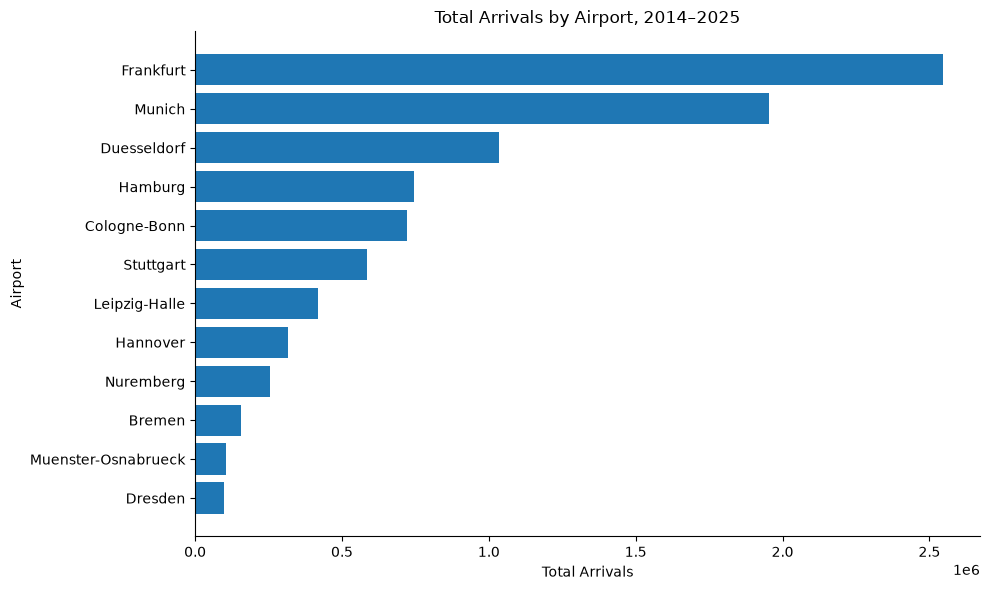

In [4]:
# ============================================================
# 4. TRAFFIC BY AIRPORT
# ============================================================
# Total arrivals per airport over the whole period. Ascending order puts the
# busiest airport at the top of the horizontal bar chart.

traffic_airport = (
    df.groupby("airport_name")["arrivals"]
      .sum()
      .sort_values(ascending=True)
)

print(traffic_airport)
fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    traffic_airport.index,
    traffic_airport.values
)

ax.set_title("Total Arrivals by Airport, 2014–2025")
ax.set_xlabel("Total Arrivals")
ax.set_ylabel("Airport")

# Remove unnecessary chart borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

In [5]:
# ============================================================
# 5. TRAFFIC SHARE BY AIRPORT
# ============================================================
# Each airport's percentage of all arrivals, reusing the totals from section 4.
traffic_share = (
    traffic_airport
    / traffic_airport.sum()
    * 100
)

print(traffic_share)

airport_name
Dresden                 1.113009
Muenster-Osnabrueck     1.185370
Bremen                  1.755155
Nuremberg               2.837809
Hannover                3.555270
Leipzig-Halle           4.680994
Stuttgart               6.541069
Cologne-Bonn            8.084648
Hamburg                 8.322537
Duesseldorf            11.583563
Munich                 21.856052
Frankfurt              28.484524
Name: arrivals, dtype: float64


In [6]:
# ============================================================
# 6. ANNUAL TRAFFIC TREND
# ============================================================
# Total arrivals across all airports per year, to show how traffic changed over
# time, including the COVID years.

annual_traffic = (
    df.groupby("year")["arrivals"]
      .sum()
)

print(annual_traffic)

year
2014    843576.0
2015    850147.0
2016    862476.0
2017    881852.0
2018    915208.0
2019    917925.0
2020    383465.0
2021    429986.0
2022    657375.0
2023    708412.0
2024    732015.0
2025    751990.0
Name: arrivals, dtype: float64


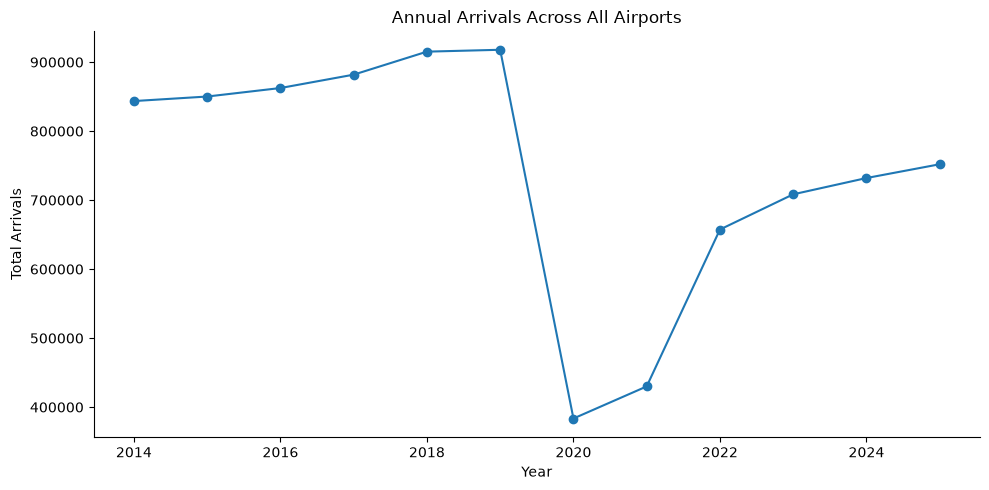

In [7]:
# Line chart of the annual totals from section 6.
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    annual_traffic.index,
    annual_traffic.values,
    marker="o"
)

ax.set_title("Annual Arrivals Across All Airports")
ax.set_xlabel("Year")
ax.set_ylabel("Total Arrivals")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

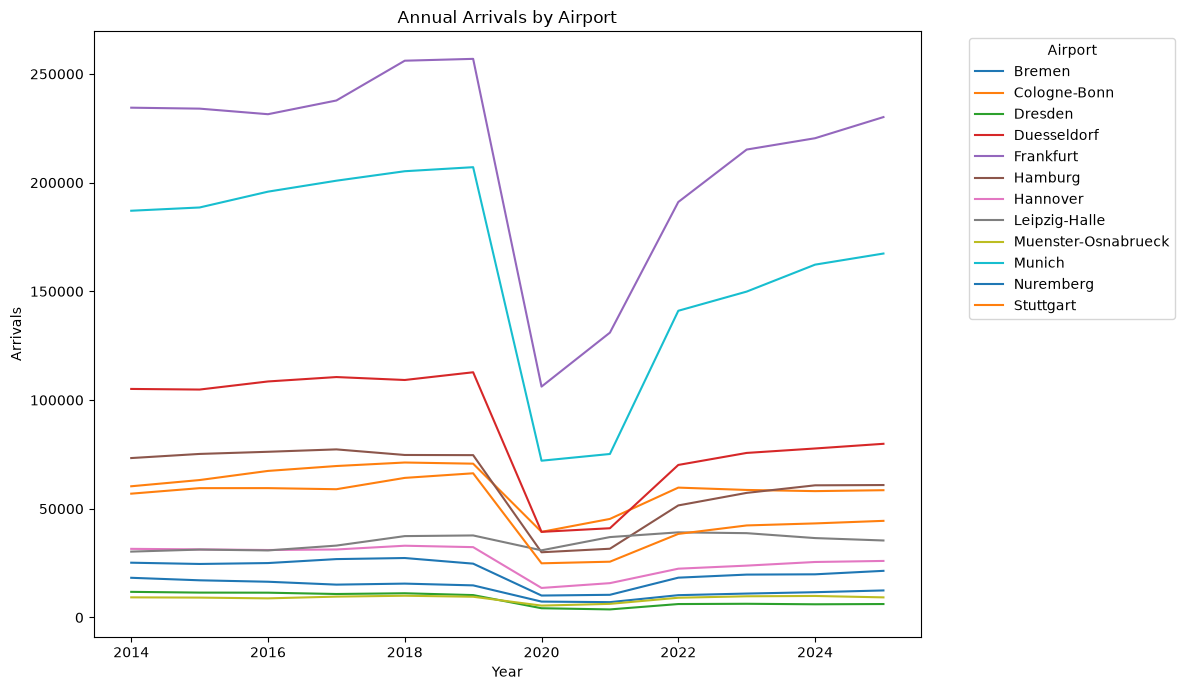

In [8]:
# ============================================================
# 7. TRAFFIC BY AIRPORT OVER TIME
# ============================================================
# Annual arrivals per airport. unstack() moves the airport level of the index into
# columns, so .plot() draws one line per airport.
traffic_airport_year = (
    df.groupby(
        ["year", "airport_name"]
    )["arrivals"]
    .sum()
    .unstack()
)

traffic_airport_year.plot(
    figsize=(12, 7)
)

plt.title("Annual Arrivals by Airport")
plt.xlabel("Year")
plt.ylabel("Arrivals")
plt.legend(
    title="Airport",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

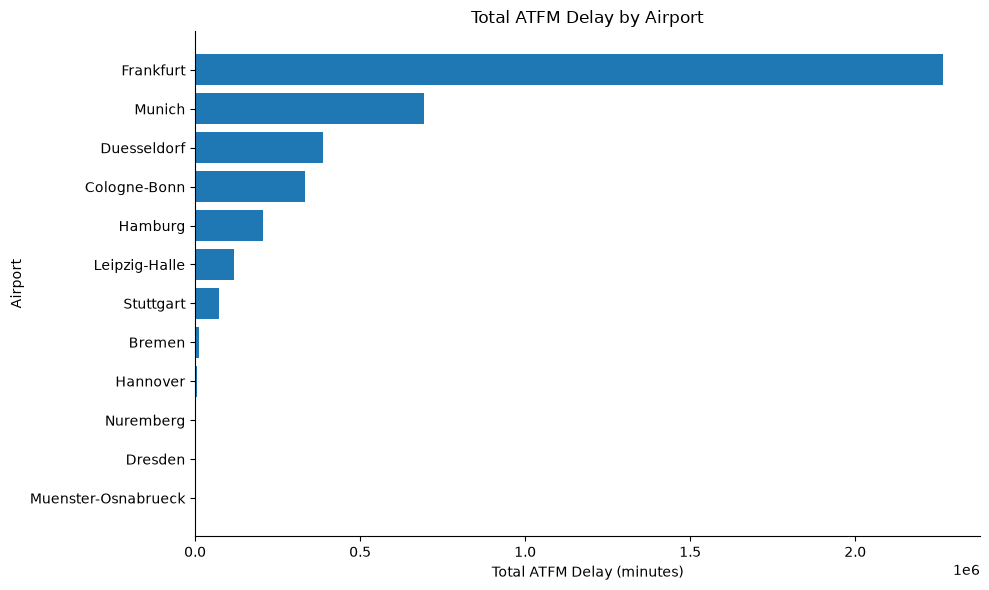

In [9]:
# ============================================================
# 8. TOTAL ATFM DELAY BY AIRPORT
# ============================================================
# Total ATFM delay minutes per airport. These are absolute totals, so large airports
# dominate; section 9 corrects for traffic volume.

airport_delay = (
    df.groupby("airport_name")["atfm_delay_min"]
      .sum()
      .sort_values(ascending=True)
)

fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    airport_delay.index,
    airport_delay.values
)

ax.set_title("Total ATFM Delay by Airport")
ax.set_xlabel("Total ATFM Delay (minutes)")
ax.set_ylabel("Airport")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

                     total_arrivals  total_delay  delay_per_1000
airport_name                                                    
Muenster-Osnabrueck        105906.0         61.0        0.575982
Nuremberg                  253542.0       1090.0        4.299090
Dresden                     99441.0        661.0        6.647158
Hannover                   317643.0       5957.0       18.753758
Bremen                     156813.0      12470.0       79.521468
Stuttgart                  584407.0      71024.0      121.531741
Hamburg                    743571.0     205862.0      276.855875
Leipzig-Halle              418220.0     117345.0      280.581990
Munich                    1952713.0     692344.0      354.554919
Duesseldorf               1034925.0     386093.0      373.063749
Cologne-Bonn               722317.0     333225.0      461.327921
Frankfurt                 2544929.0    2264711.0      889.891624


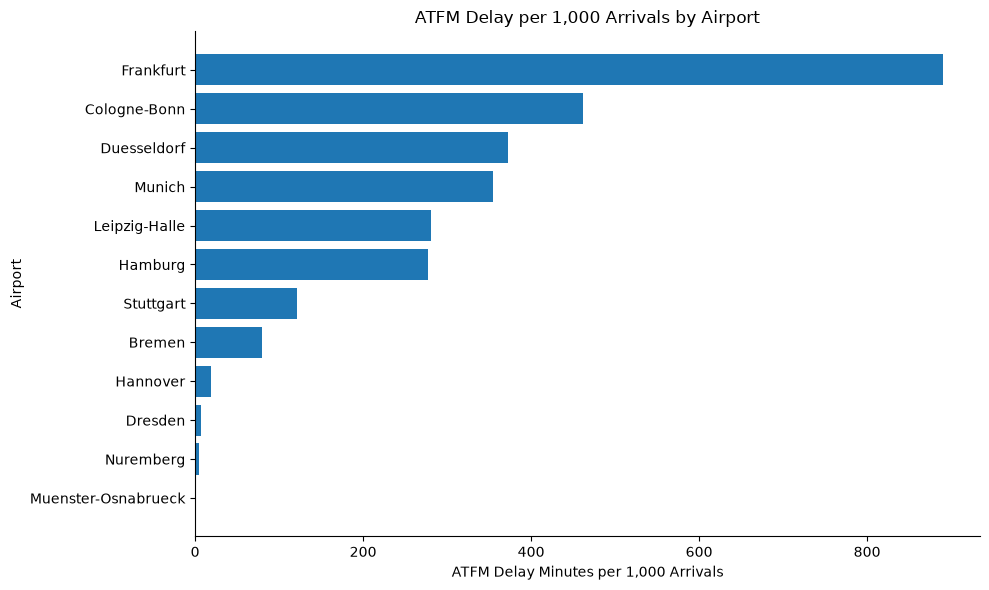

In [10]:
# ============================================================
# 9. DELAY PER 1,000 ARRIVALS BY AIRPORT
# ============================================================
# Delay intensity per airport = total delay minutes / total arrivals * 1,000.
# A ratio of sums, not a mean of daily ratios, so quiet days with few arrivals
# do not count as much as busy days.

airport_performance = (
    df.groupby("airport_name")
      .agg(
          total_arrivals=("arrivals", "sum"),
          total_delay=("atfm_delay_min", "sum")
      )
)

airport_performance["delay_per_1000"] = (
    airport_performance["total_delay"]
    / airport_performance["total_arrivals"]
    * 1000
)

airport_performance = (
    airport_performance
    .sort_values("delay_per_1000")
)

print(airport_performance)
fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    airport_performance.index,
    airport_performance["delay_per_1000"]
)

ax.set_title("ATFM Delay per 1,000 Arrivals by Airport")
ax.set_xlabel("ATFM Delay Minutes per 1,000 Arrivals")
ax.set_ylabel("Airport")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

airport_name
Muenster-Osnabrueck    0.000458
Dresden                0.000916
Nuremberg              0.001597
Hannover               0.007757
Bremen                 0.021918
Stuttgart              0.039386
Leipzig-Halle          0.052247
Hamburg                0.065252
Munich                 0.102898
Duesseldorf            0.119325
Cologne-Bonn           0.135980
Frankfurt              0.193931
Name: disrupted_day, dtype: float64


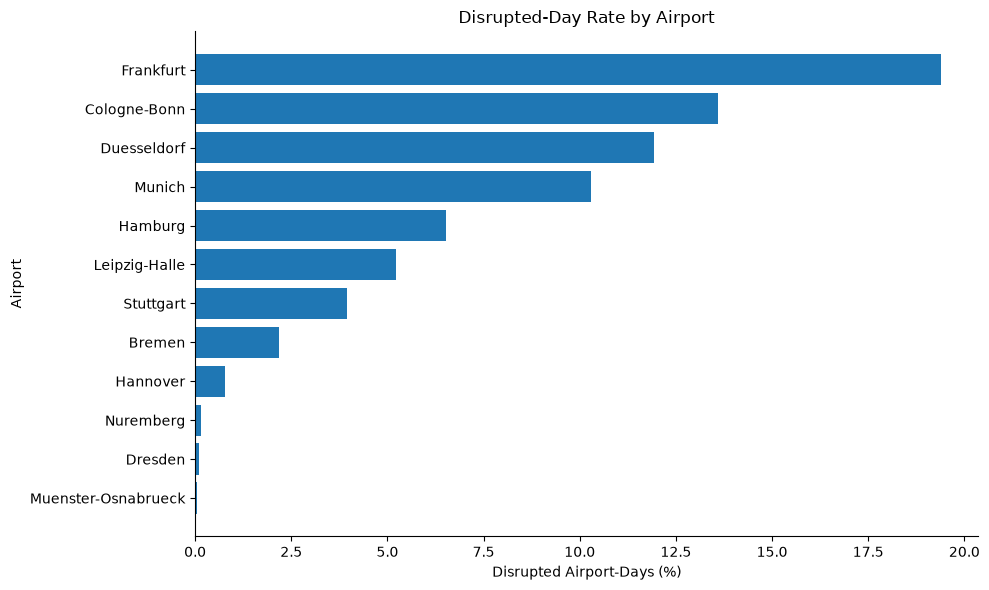

In [11]:
# ============================================================
# 10. DISRUPTION RATE BY AIRPORT
# ============================================================
# Share of airport-days flagged as disrupted (at least 2% of arrivals with more
# than 15 min ATFM delay). The mean of the 0/1 column is that share.

airport_disruption = (
    df.groupby("airport_name")["disrupted_day"]
      .mean()
      .sort_values()
)

print(airport_disruption)
fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    airport_disruption.index,
    airport_disruption.values * 100
)

ax.set_title("Disrupted-Day Rate by Airport")
ax.set_xlabel("Disrupted Airport-Days (%)")
ax.set_ylabel("Airport")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

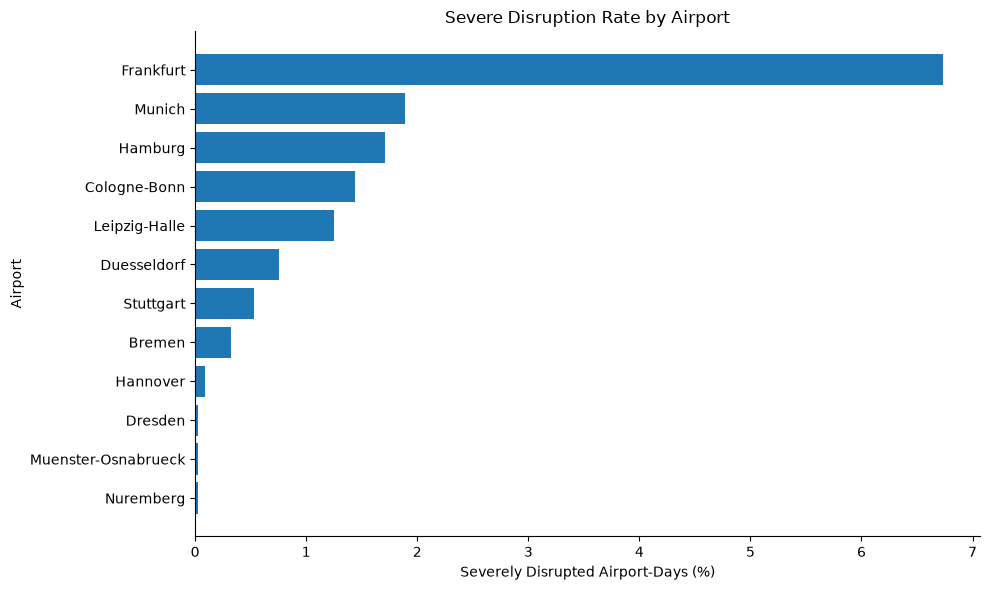

In [12]:
# ============================================================
# 11. SEVERE DISRUPTION RATE
# ============================================================
# Same as section 10, using the stricter severe_disrupted_day flag.
severe_rate = (
    df.groupby("airport_name")
      ["severe_disrupted_day"]
      .mean()
      .sort_values()
)

fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    severe_rate.index,
    severe_rate.values * 100
)

ax.set_title("Severe Disruption Rate by Airport")
ax.set_xlabel("Severely Disrupted Airport-Days (%)")
ax.set_ylabel("Airport")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

      arrivals     delay  delay_per_1000
year                                    
2014  843576.0  466887.0      553.461692
2015  850147.0  305598.0      359.464893
2016  862476.0  402567.0      466.757336
2017  881852.0  453598.0      514.369758
2018  915208.0  476287.0      520.413939
2019  917925.0  444249.0      483.970913
2020  383465.0   42670.0      111.274823
2021  429986.0   86187.0      200.441410
2022  657375.0  210492.0      320.200799
2023  708412.0  457395.0      645.662411
2024  732015.0  400111.0      546.588526
2025  751990.0  344802.0      458.519395


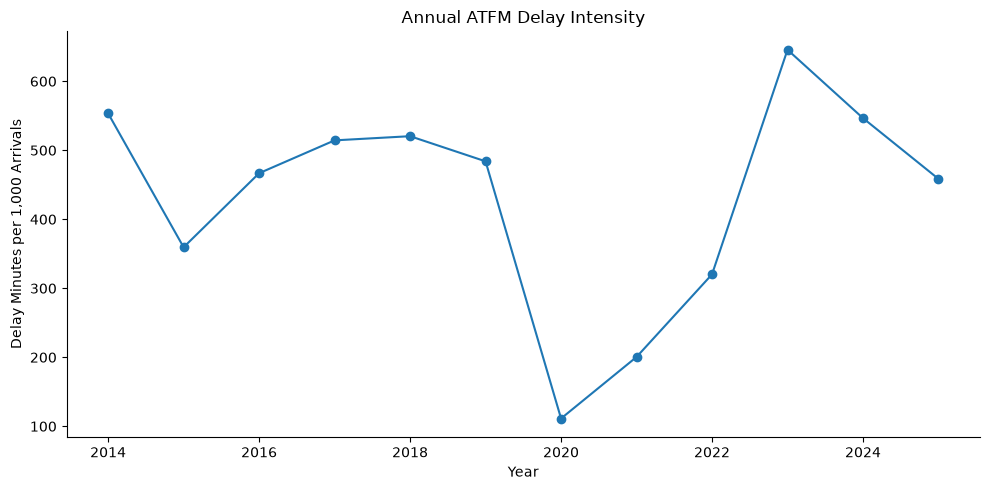

In [13]:
# ============================================================
# 12. ANNUAL DELAY INTENSITY
# ============================================================
# Delay minutes per 1,000 arrivals for each year across all airports, again as
# a ratio of the yearly sums.

annual_delay = (
    df.groupby("year")
      .agg(
          arrivals=("arrivals", "sum"),
          delay=("atfm_delay_min", "sum")
      )
)

annual_delay["delay_per_1000"] = (
    annual_delay["delay"]
    / annual_delay["arrivals"]
    * 1000
)

print(annual_delay)
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    annual_delay.index,
    annual_delay["delay_per_1000"],
    marker="o"
)

ax.set_title("Annual ATFM Delay Intensity")
ax.set_xlabel("Year")
ax.set_ylabel("Delay Minutes per 1,000 Arrivals")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

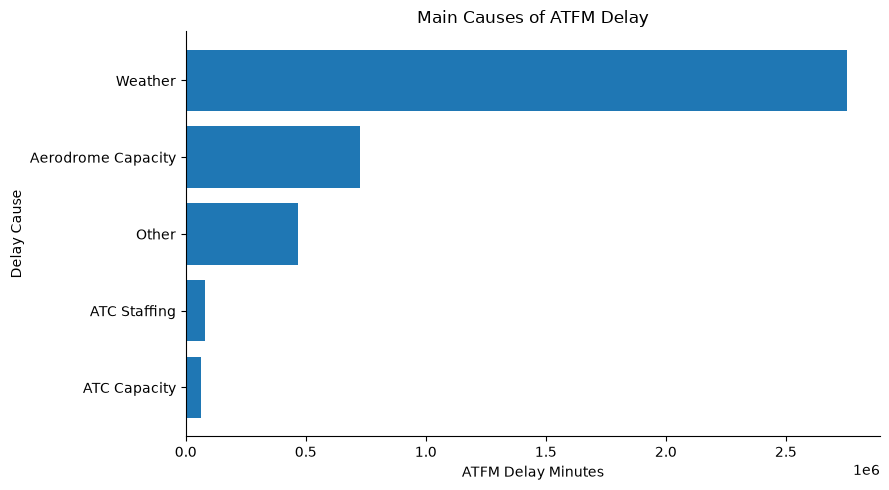

In [14]:
# ============================================================
# 13. ATFM DELAY CAUSES
# ============================================================
# Total ATFM delay minutes by cause. The four named causes do not cover every
# minute, so the remainder is shown as "Other".

cause_columns = {
    "Weather": "delay_weather_min",
    "Aerodrome Capacity": "delay_aerodrome_capacity_min",
    "ATC Capacity": "delay_atc_capacity_min",
    "ATC Staffing": "delay_atc_staffing_min"
}
# Sum of delay minutes for each named cause
cause_totals = pd.Series({
    name: df[column].sum()
    for name, column in cause_columns.items()
})
known_causes = cause_totals.sum()

total_delay = df["atfm_delay_min"].sum()

# max(..., 0) prevents a negative remainder if the cause columns ever add up
# to more than the total
other_delay = max(
    total_delay - known_causes,
    0
)

cause_totals["Other"] = other_delay

cause_totals = cause_totals.sort_values()
fig, ax = plt.subplots(figsize=(9, 5))

ax.barh(
    cause_totals.index,
    cause_totals.values
)

ax.set_title("Main Causes of ATFM Delay")
ax.set_xlabel("ATFM Delay Minutes")
ax.set_ylabel("Delay Cause")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

Airport-days missing at least one weather reading: 1067


  Weather condition  With condition  Without condition
0      Thunderstorm        0.177712           0.055179
1    Low visibility        0.108624           0.056631
2       Strong gust        0.088326           0.057664
3              Snow        0.063864           0.061401
4          Freezing        0.099251           0.061185


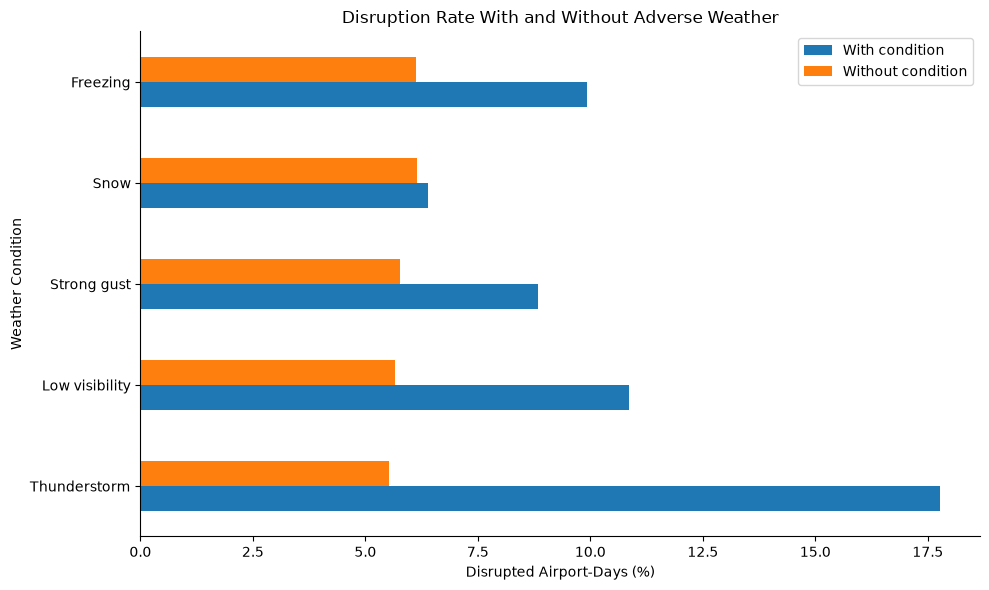

In [15]:
# ============================================================
# 14. DEFINE ADVERSE WEATHER EVENTS
# ============================================================
# Turn the hourly weather counts into yes/no flags per airport-day, and mark
# which days have all five weather readings.

# Weather column behind each weather condition
weather_sources = {
    "Thunderstorm": "thunder_hours",
    "Low visibility": "low_vis_hours_lt1000",
    "Strong gust": "gust_hours_ge15",
    "Snow": "snow_hours",
    "Freezing": "freezing_hours"
}

# True means that this weather condition occurred
# at least once during the airport-day.
for event, column in weather_sources.items():
    df[event] = df[column] > 0

# Days without a weather reading would otherwise count as
# "no event", so the comparisons below leave them out.
weather_observed = (
    df[list(weather_sources.values())]
    .notna()
    .all(axis=1)
)

print(
    "Airport-days missing at least one weather reading:",
    (~weather_observed).sum()
)
# ============================================================
# 15. WEATHER-DISRUPTION ASSOCIATION
# ============================================================
# For each weather condition, compare the disruption rate on days with and
# without it. Each comparison uses only days with a reading for that condition.

def calculate_weather_risk(data, event):
    """
    Calculate the disruption rate when a weather event is present
    and when it is absent, using only days with a reading
    for that weather condition.

    Args:
        data: the airport-day table.
        event: one of the weather flag names, e.g. "Thunderstorm".

    Returns:
        (rate with the event, rate without the event) as shares between 0 and 1.
    """

    # Drop days where this condition's weather column is missing
    observed = data[
        data[weather_sources[event]].notna()
    ]

    with_event = observed.loc[
        observed[event],
        "disrupted_day"
    ].mean()

    without_event = observed.loc[
        ~observed[event],
        "disrupted_day"
    ].mean()

    return with_event, without_event
    
weather_events = [
    "Thunderstorm",
    "Low visibility",
    "Strong gust",
    "Snow",
    "Freezing"
]

weather_results = []

for event in weather_events:

    with_event, without_event = (
        calculate_weather_risk(df, event)
    )

    weather_results.append({
        "Weather condition": event,
        "With condition": with_event,
        "Without condition": without_event
    })

weather_results = pd.DataFrame(weather_results)

print(weather_results)

# Shares to percentages for the chart
weather_plot = (
    weather_results
    .set_index("Weather condition")
    * 100
)

ax = weather_plot.plot(
    kind="barh",
    figsize=(10, 6)
)

ax.set_title(
    "Disruption Rate With and Without Adverse Weather"
)

ax.set_xlabel("Disrupted Airport-Days (%)")
ax.set_ylabel("Weather Condition")

ax.legend(
    title=""
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

gust_duration_group
0 hours      5.766393
1–3 hours    9.507640
4–6 hours    6.644239
7+ hours     8.712871
Name: disrupted_day, dtype: float64


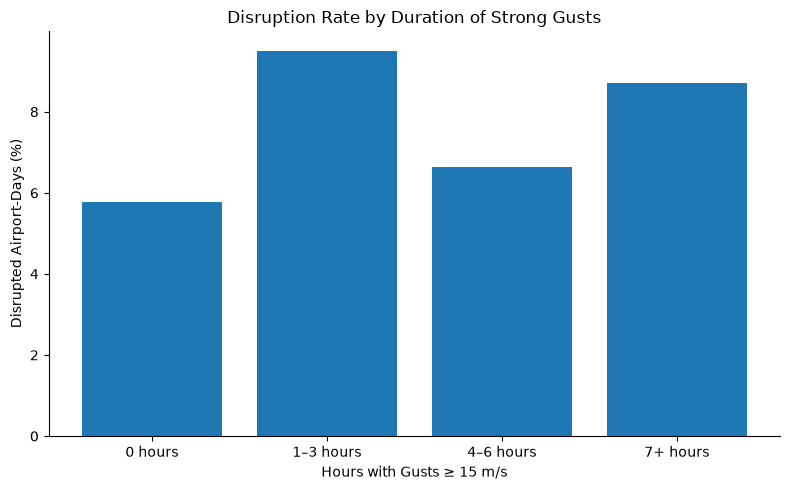

In [16]:
# ============================================================
# 16. WEATHER SEVERITY / DURATION
# ============================================================
# Disruption rate by how many hours of strong gusts (at least 15 m/s) a day had.
# The first bin edge -1 makes 0 hours its own group; days without a gust reading
# get no group and drop out of the groupby.

df["gust_duration_group"] = pd.cut(
    df["gust_hours_ge15"],
    bins=[-1, 0, 3, 6, np.inf],
    labels=[
        "0 hours",
        "1–3 hours",
        "4–6 hours",
        "7+ hours"
    ]
)
gust_disruption = (
    df.groupby(
        "gust_duration_group",
        # Only keep groups that actually occur (option for categorical group keys)
        observed=True
    )["disrupted_day"]
    .mean()
    * 100
)

print(gust_disruption)

fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(
    gust_disruption.index.astype(str),
    gust_disruption.values
)

ax.set_title(
    "Disruption Rate by Duration of Strong Gusts"
)

ax.set_xlabel(
    "Hours with Gusts ≥ 15 m/s"
)

ax.set_ylabel(
    "Disrupted Airport-Days (%)"
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

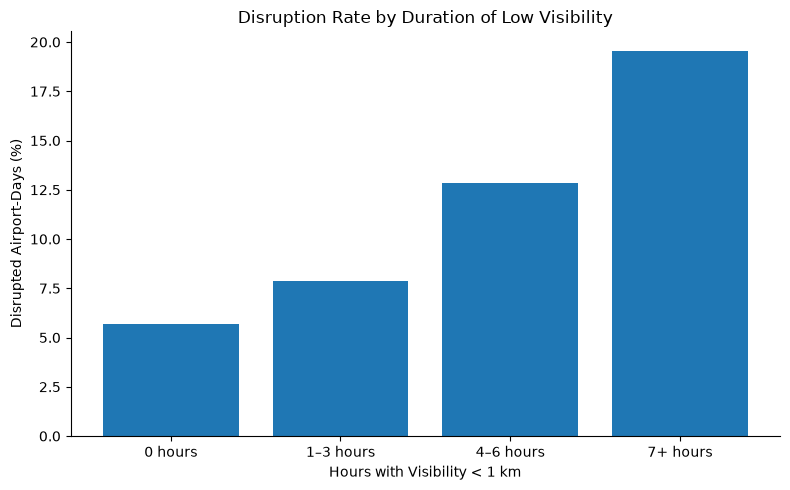

In [17]:
# Same duration analysis for low visibility (under 1 km), with the same bins.
df["low_visibility_group"] = pd.cut(
    df["low_vis_hours_lt1000"],
    bins=[-1, 0, 3, 6, np.inf],
    labels=[
        "0 hours",
        "1–3 hours",
        "4–6 hours",
        "7+ hours"
    ]
)

visibility_disruption = (
    df.groupby(
        "low_visibility_group",
        observed=True
    )["disrupted_day"]
    .mean()
    * 100
)

fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(
    visibility_disruption.index.astype(str),
    visibility_disruption.values
)

ax.set_title(
    "Disruption Rate by Duration of Low Visibility"
)

ax.set_xlabel(
    "Hours with Visibility < 1 km"
)

ax.set_ylabel(
    "Disrupted Airport-Days (%)"
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

               Normal weather  Adverse weather
traffic_group                                 
Low                  0.484966         2.441569
Normal               3.198071        10.603589
High                 6.729191        17.164876
Very high            7.166667         8.132992


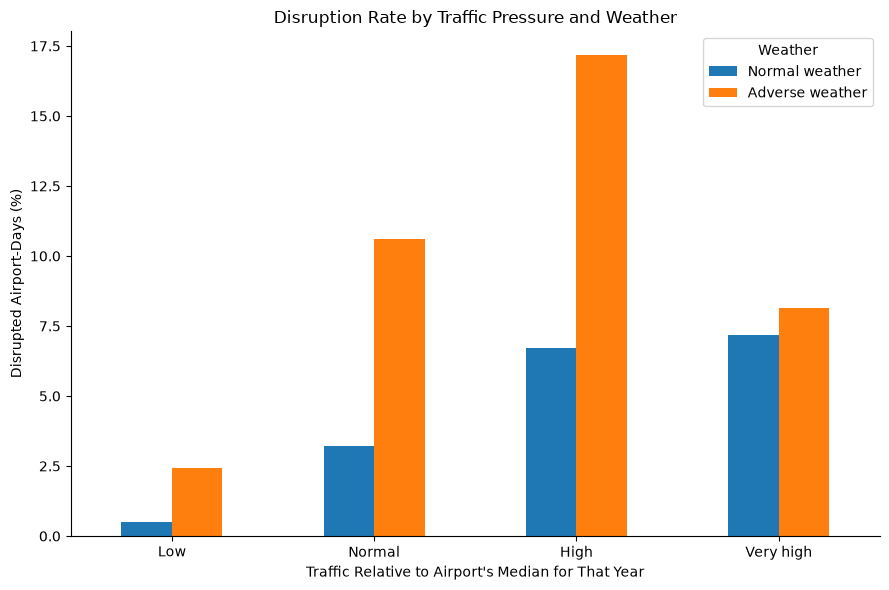

In [18]:
# ============================================================
# 17. RELATIVE TRAFFIC PRESSURE
# ============================================================
# Traffic pressure = arrivals / the airport's median arrivals in the same year,
# then grouped into four bands (up to 0.8, 0.8-1.0, 1.0-1.2, above 1.2).

# Compare each day with the airport's median for the SAME YEAR.
# An all-years median would label almost every COVID-era day
# "Low" and most pre-COVID days "Very high".
# transform() returns the group median on every row, aligned with df
airport_median_traffic = (
    df.groupby(["airport_icao", "year"])["arrivals"]
      .transform("median")
)

df["traffic_pressure"] = (
    df["arrivals"]
    / airport_median_traffic
)

df["traffic_group"] = pd.cut(
    df["traffic_pressure"],
    bins=[
        -np.inf,
        0.8,
        1.0,
        1.2,
        np.inf
    ],
    labels=[
        "Low",
        "Normal",
        "High",
        "Very high"
    ]
)

# True if at least one of the five conditions occurred that day
df["adverse_weather"] = (
    df["Thunderstorm"]
    | df["Low visibility"]
    | df["Strong gust"]
    | df["Snow"]
    | df["Freezing"]
)

# ============================================================
# TRAFFIC × WEATHER INTERACTION
# ============================================================
# Disruption rate for each traffic band, split by whether any adverse weather
# occurred. unstack() puts the two weather states (False, True) into columns.

# Only days with all five weather readings
traffic_weather = (
    df[weather_observed]
    .groupby(
        ["traffic_group", "adverse_weather"],
        observed=True
    )["disrupted_day"]
    .mean()
    .unstack()
    * 100
)

# Columns come out in False, True order, so they are renamed in that order
traffic_weather.columns = [
    "Normal weather",
    "Adverse weather"
]

print(traffic_weather)

ax = traffic_weather.plot(
    kind="bar",
    figsize=(9, 6)
)

ax.set_title(
    "Disruption Rate by Traffic Pressure and Weather"
)

ax.set_xlabel(
    "Traffic Relative to Airport's Median for That Year"
)

ax.set_ylabel(
    "Disrupted Airport-Days (%)"
)

ax.legend(
    title="Weather"
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.xticks(rotation=0)

plt.tight_layout()
plt.show()